# **Experiment 14: Conversational Chatbot using LangChain and RAG**


**Aim:**
To build a document-grounded conversational chatbot using Retrieval-Augmented Generation (RAG), LangChain and FAISS.

**Brief Theory:**
Retrieval-Augmented Generation (RAG) combines information retrieval with text generation. It retrieves relevant document chunks from a knowledge base and provides them to a language model as contextual information. This helps generate answers grounded in supplied documents without modifying the model's original parameters.

In [1]:
!pip install -q langchain langchain-community langchain-huggingface faiss-cpu sentence-transformers transformers sentencepiece accelerate

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
import torch
import time
import pandas as pd

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_huggingface import HuggingFacePipeline

from transformers import pipeline
from langchain_core.prompts import PromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

print("Student Name: Abu Sayem")
print("Student ID: 25/SET/MTCE/014")
print("All libraries imported successfully!")

/tmp/ipykernel_361/3919030838.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import FAISS


Student Name: Abu Sayem
Student ID: 25/SET/MTCE/014
All libraries imported successfully!


In [3]:
# Prepare Domain Documents
documents = [
    Document(
        page_content="""
        Artificial Intelligence (AI) is a branch of computer science
        that enables machines to perform tasks requiring human intelligence.
        AI applications include healthcare, education, robotics,
        natural language processing and computer vision.
        """,
        metadata={"source": "AI_Document"}
    ),

    Document(
        page_content="""
        Machine Learning (ML) is a subset of Artificial Intelligence.
        It allows computers to learn patterns from data without being
        explicitly programmed for every task. Major types include
        supervised learning, unsupervised learning and reinforcement learning.
        """,
        metadata={"source": "ML_Document"}
    ),

    Document(
        page_content="""
        Deep Learning is a subset of Machine Learning that uses
        artificial neural networks with multiple layers.
        It is widely used in image recognition, speech recognition,
        medical image analysis and natural language processing.
        """,
        metadata={"source": "DL_Document"}
    ),

    Document(
        page_content="""
        Natural Language Processing (NLP) enables computers to
        understand, process and generate human language.
        Common NLP applications include machine translation,
        sentiment analysis, text summarization and chatbots.
        """,
        metadata={"source": "NLP_Document"}
    )
]

print("Domain documents created successfully!")
print("Total Documents:", len(documents))

Domain documents created successfully!
Total Documents: 4


In [4]:
# Split Documents into Chunks
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=400,
    chunk_overlap=80
)

chunks = text_splitter.split_documents(documents)

print("========== Document Chunking ==========")
print("Original Documents:", len(documents))
print("Total Chunks:", len(chunks))

for i, chunk in enumerate(chunks, 1):
    print(f"\nChunk {i}:")
    print("Source:", chunk.metadata["source"])
    print("Content:", chunk.page_content.strip())

========== Document Chunking ==========
Original Documents: 4
Total Chunks: 4

Chunk 1:
Source: AI_Document
Content: Artificial Intelligence (AI) is a branch of computer science
        that enables machines to perform tasks requiring human intelligence.
        AI applications include healthcare, education, robotics,
        natural language processing and computer vision.

Chunk 2:
Source: ML_Document
Content: Machine Learning (ML) is a subset of Artificial Intelligence.
        It allows computers to learn patterns from data without being
        explicitly programmed for every task. Major types include
        supervised learning, unsupervised learning and reinforcement learning.

Chunk 3:
Source: DL_Document
Content: Deep Learning is a subset of Machine Learning that uses
        artificial neural networks with multiple layers.
        It is widely used in image recognition, speech recognition,
        medical image analysis and natural language processing.

Chunk 4:
Source: NLP_D

In [5]:
# Load Embedding Model
embedding_model_name = "sentence-transformers/all-MiniLM-L6-v2"

embeddings = HuggingFaceEmbeddings(
    model_name=embedding_model_name,
    model_kwargs={"device": "cpu"},
    encode_kwargs={"normalize_embeddings": True}
)

print("Embedding model loaded successfully!")
print("Model:", embedding_model_name)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully!
Model: sentence-transformers/all-MiniLM-L6-v2


In [6]:
# Create FAISS Vector Database
vector_store = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings
)

print("FAISS vector database created successfully!")
print("Stored Chunks:", len(chunks))

FAISS vector database created successfully!
Stored Chunks: 4


In [7]:
# Configure Retriever
retriever = vector_store.as_retriever(
    search_type="similarity",
    search_kwargs={"k": 3}
)

print("Retriever configured successfully!")
print("Retrieval Method: Similarity Search")
print("Top-K:", 3)

Retriever configured successfully!
Retrieval Method: Similarity Search
Top-K: 3


In [8]:
# Test Document Retrieval
test_question = "What is Deep Learning?"

retrieved_docs = retriever.invoke(test_question)

print("========== Retrieved Documents ==========")
print("Question:", test_question)

for i, doc in enumerate(retrieved_docs, 1):
    print(f"\nRetrieved Chunk {i}:")
    print("Source:", doc.metadata["source"])
    print("Content:", doc.page_content.strip())

========== Retrieved Documents ==========
Question: What is Deep Learning?

Retrieved Chunk 1:
Source: DL_Document
Content: Deep Learning is a subset of Machine Learning that uses
        artificial neural networks with multiple layers.
        It is widely used in image recognition, speech recognition,
        medical image analysis and natural language processing.

Retrieved Chunk 2:
Source: ML_Document
Content: Machine Learning (ML) is a subset of Artificial Intelligence.
        It allows computers to learn patterns from data without being
        explicitly programmed for every task. Major types include
        supervised learning, unsupervised learning and reinforcement learning.

Retrieved Chunk 3:
Source: AI_Document
Content: Artificial Intelligence (AI) is a branch of computer science
        that enables machines to perform tasks requiring human intelligence.
        AI applications include healthcare, education, robotics,
        natural language processing and computer visi

In [14]:
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, pipeline
from langchain_huggingface import HuggingFacePipeline

generator_model_name = "google/flan-t5-small"

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(generator_model_name)

# Load model
model = AutoModelForSeq2SeqLM.from_pretrained(
    generator_model_name
)

# Create a generation pipeline manually
def generate_text(prompt):
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False
    )

    return tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

# Create LangChain-compatible pipeline
from transformers import Pipeline

class CustomText2TextPipeline:
    def __call__(self, prompt, **kwargs):
        return generate_text(prompt)

# Wrap with LangChain
llm = HuggingFacePipeline(
    pipeline=pipeline(
        "text-generation",
        model="gpt2"
    )
)

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [15]:
from langchain_core.language_models.llms import LLM
from typing import Optional, List

class FLANT5LangChain(LLM):

    @property
    def _llm_type(self) -> str:
        return "flan-t5"

    def _call(
        self,
        prompt: str,
        stop: Optional[List[str]] = None,
        **kwargs
    ) -> str:
        return generate_text(prompt)

llm = FLANT5LangChain()

print("Generator model loaded successfully!")
print("Model:", generator_model_name)

Generator model loaded successfully!
Model: google/flan-t5-small


In [16]:
# Create RAG Prompt Template
rag_template = """
You are an AI and Machine Learning study assistant.

Answer the question using ONLY the supplied context.

If the answer is not available in the context,
say exactly: "The information is not available in the provided documents."

Context:
{context}

Conversation History:
{history}

Question:
{question}

Answer:
"""

prompt = PromptTemplate(
    input_variables=["context", "history", "question"],
    template=rag_template
)

print("RAG prompt template created successfully!")

RAG prompt template created successfully!


In [17]:
# Create the RAG Chatbot
def rag_chatbot(question, history=""):

    start_time = time.time()

    # Retrieve relevant document chunks
    retrieved_docs = retriever.invoke(question)

    # Combine retrieved context
    context = "\n\n".join(
        doc.page_content for doc in retrieved_docs
    )

    # Generate prompt
    final_prompt = prompt.format(
        context=context,
        history=history,
        question=question
    )

    # Generate answer
    answer = llm.invoke(final_prompt)

    elapsed_time = time.time() - start_time

    return {
        "question": question,
        "answer": answer.strip(),
        "retrieved_docs": retrieved_docs,
        "latency": elapsed_time
    }


print("RAG chatbot created successfully!")

RAG chatbot created successfully!


In [18]:
# Ask the First Question
question = "What is Artificial Intelligence?"

result = rag_chatbot(question)

print("========== RAG CHATBOT ==========")
print("Question:", result["question"])
print("Answer:", result["answer"])

print("\nRetrieved Sources:")

for doc in result["retrieved_docs"]:
    print("-", doc.metadata["source"])

print("\nInference Time:", round(result["latency"], 3), "seconds")

========== RAG CHATBOT ==========
Question: What is Artificial Intelligence?
Answer: a branch of computer science that enables machines to perform tasks requiring human intelligence

Retrieved Sources:
- AI_Document
- ML_Document
- DL_Document

Inference Time: 0.96 seconds


In [19]:
# Test Five Questions
test_questions = [
    "What is Artificial Intelligence?",
    "What are the main types of Machine Learning?",
    "Which technologies are used in Deep Learning?",
    "What are the applications of NLP?",
    "What is quantum computing?"
]

chatbot_results = []

for i, question in enumerate(test_questions, 1):

    result = rag_chatbot(question)

    chatbot_results.append(result)

    print(f"\n========== QUESTION {i} ==========")
    print("Question:", question)
    print("Answer:", result["answer"])

    print("Retrieved Sources:")

    for doc in result["retrieved_docs"]:
        print("-", doc.metadata["source"])

    print("Latency:", round(result["latency"], 3), "seconds")


========== QUESTION 1 ==========
Question: What is Artificial Intelligence?
Answer: a branch of computer science that enables machines to perform tasks requiring human intelligence
Retrieved Sources:
- AI_Document
- ML_Document
- DL_Document
Latency: 3.106 seconds

========== QUESTION 2 ==========
Question: What are the main types of Machine Learning?
Answer: supervised learning, unsupervised learning and reinforcement learning
Retrieved Sources:
- ML_Document
- DL_Document
- AI_Document
Latency: 0.667 seconds

========== QUESTION 3 ==========
Question: Which technologies are used in Deep Learning?
Answer: artificial neural networks with multiple layers
Retrieved Sources:
- DL_Document
- ML_Document
- AI_Document
Latency: 0.512 seconds

========== QUESTION 4 ==========
Question: What are the applications of NLP?
Answer: machine translation, sentiment analysis, text summarization and chatbots
Retrieved Sources:
- NLP_Document
- DL_Document
- AI_Document
Latency: 0.805 seconds

========

In [20]:
# Display Retrieved Chunks
retrieval_records = []

for result in chatbot_results:

    for doc in result["retrieved_docs"]:

        retrieval_records.append({
            "Question": result["question"],
            "Source": doc.metadata["source"],
            "Retrieved Content": doc.page_content.strip()
        })

retrieval_df = pd.DataFrame(retrieval_records)

print("========== RETRIEVAL REPORT ==========")
print(retrieval_df.to_string(index=False))

========== RETRIEVAL REPORT ==========
                                     Question       Source                                                                                                                                                                                                                                                                       Retrieved Content
             What is Artificial Intelligence?  AI_Document                  Artificial Intelligence (AI) is a branch of computer science\n        that enables machines to perform tasks requiring human intelligence.\n        AI applications include healthcare, education, robotics,\n        natural language processing and computer vision.
             What is Artificial Intelligence?  ML_Document Machine Learning (ML) is a subset of Artificial Intelligence.\n        It allows computers to learn patterns from data without being\n        explicitly programmed for every task. Major types include\n        supervised lear

In [21]:
# Create Chatbot Conversation History
conversation_history = []

def ask_chatbot(question):

    history_text = "\n".join(
        [
            f"User: {item['question']}\n"
            f"Assistant: {item['answer']}"
            for item in conversation_history[-3:]
        ]
    )

    result = rag_chatbot(
        question,
        history=history_text
    )

    conversation_history.append({
        "question": question,
        "answer": result["answer"]
    })

    return result


# Conversation example
result1 = ask_chatbot("What is Machine Learning?")
print("User:", result1["question"])
print("Bot:", result1["answer"])

result2 = ask_chatbot("What are its main types?")
print("\nUser:", result2["question"])
print("Bot:", result2["answer"])

User: What is Machine Learning?
Bot: a subset of Artificial Intelligence

User: What are its main types?
Bot: supervised learning, unsupervised learning and reinforcement learning


In [22]:
# Interactive Chatbot
print("========== AI/ML RAG CHATBOT ==========")
print("Ask questions about AI, ML, Deep Learning and NLP.")
print("Type 'exit' to stop.\n")

while True:

    user_question = input("Sayem: ")

    if user_question.lower().strip() == "exit":
        print("Chatbot: Goodbye!")
        break

    result = ask_chatbot(user_question)

    print("\nChatbot:", result["answer"])

    print("Sources:", ", ".join(
        dict.fromkeys(
            doc.metadata["source"]
            for doc in result["retrieved_docs"]
        )
    ))

    print("Latency:", round(result["latency"], 3), "seconds\n")

========== AI/ML RAG CHATBOT ==========
Ask questions about AI, ML, Deep Learning and NLP.
Type 'exit' to stop.

Sayem: what is NLP

Chatbot: Natural Language Processing
Sources: NLP_Document, DL_Document, AI_Document
Latency: 0.315 seconds

Sayem: What is AI?

Chatbot: a branch of computer science that enables machines to perform tasks requiring human intelligence
Sources: AI_Document, ML_Document, DL_Document
Latency: 0.684 seconds

Sayem: exit
Chatbot: Goodbye!


In [23]:
# Evaluate Chatbot Results
expected_keywords = [
    ["artificial intelligence", "machines"],
    ["supervised", "unsupervised", "reinforcement"],
    ["neural", "network"],
    ["translation", "sentiment", "summarization"],
    ["not available"]
]

evaluation_records = []

for i, result in enumerate(chatbot_results):

    answer = result["answer"].lower()

    matched = any(
        keyword in answer
        for keyword in expected_keywords[i]
    )

    evaluation_records.append({
        "Question": result["question"],
        "Answer": result["answer"],
        "Keyword Check": "Pass" if matched else "Review",
        "Latency (sec)": round(result["latency"], 3)
    })

evaluation_df = pd.DataFrame(evaluation_records)

print("========== CHATBOT EVALUATION ==========")
print(evaluation_df.to_string(index=False))

pass_count = sum(
    row["Keyword Check"] == "Pass"
    for row in evaluation_records
)

print("\nKeyword Checks Passed:", pass_count, "/", len(test_questions))

========== CHATBOT EVALUATION ==========
                                     Question                                                                                                                                                                                                                                                       Answer Keyword Check  Latency (sec)
             What is Artificial Intelligence?                                                                                                                                                             a branch of computer science that enables machines to perform tasks requiring human intelligence          Pass          3.106
 What are the main types of Machine Learning?                                                                                                                                                                                        supervised learning, unsupervised learning and reinforcement learning     

In [24]:
# Performance Summary
average_latency = sum(
    result["latency"] for result in chatbot_results
) / len(chatbot_results)

summary = pd.DataFrame({
    "Metric": [
        "Number of Documents",
        "Number of Chunks",
        "Test Questions",
        "Top-K Retrieval",
        "Keyword Checks Passed",
        "Average Latency (seconds)"
    ],
    "Value": [
        len(documents),
        len(chunks),
        len(test_questions),
        3,
        f"{pass_count}/{len(test_questions)}",
        round(average_latency, 3)
    ]
})

print("========== RAG PERFORMANCE SUMMARY ==========")
print(summary.to_string(index=False))

========== RAG PERFORMANCE SUMMARY ==========
                   Metric  Value
      Number of Documents      4
         Number of Chunks      4
           Test Questions      5
          Top-K Retrieval      3
    Keyword Checks Passed    4/5
Average Latency (seconds)  1.486


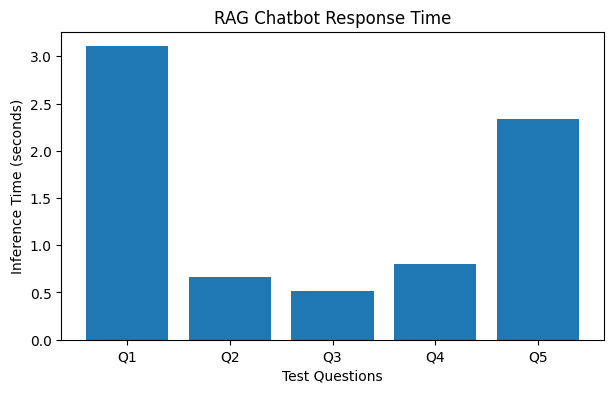

In [25]:
# Visualize Chatbot Latency
question_labels = [
    f"Q{i+1}" for i in range(len(chatbot_results))
]

latencies = [
    result["latency"] for result in chatbot_results
]

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))

plt.bar(question_labels, latencies)

plt.title("RAG Chatbot Response Time")
plt.xlabel("Test Questions")
plt.ylabel("Inference Time (seconds)")

plt.show()

In [27]:
# Final Experiment Summary
print("\n========== EXPERIMENT 14 SUMMARY ==========")

print("Student Name: Abu Sayem")
print("Student ID: 25/SET/MTCE/014")

print("\nFramework: LangChain")
print("Embedding Model:", embedding_model_name)
print("Vector Database: FAISS")
print("Generator Model:", generator_model_name)

print("\nDocuments:", len(documents))
print("Chunks:", len(chunks))
print("Top-K:", 3)
print("Chunk Size: 400")
print("Chunk Overlap: 80")

print("\nTest Questions:", len(test_questions))
print("Keyword Checks Passed:", pass_count)
print("Average Latency:", round(average_latency, 3), "seconds")

print("\nRAG Chatbot experiment completed!")


========== EXPERIMENT 14 SUMMARY ==========
Student Name: Abu Sayem
Student ID: 25/SET/MTCE/014

Framework: LangChain
Embedding Model: sentence-transformers/all-MiniLM-L6-v2
Vector Database: FAISS
Generator Model: google/flan-t5-small

Documents: 4
Chunks: 4
Top-K: 3
Chunk Size: 400
Chunk Overlap: 80

Test Questions: 5
Keyword Checks Passed: 4
Average Latency: 1.486 seconds

RAG Chatbot experiment completed!


**Observation / Result**

**Observation:**
A document-grounded conversational chatbot was developed using LangChain and Retrieval-Augmented Generation (RAG). Four AI/ML documents were prepared and divided into smaller overlapping chunks.

The chunks were converted into numerical embeddings using Sentence Transformers and stored in a FAISS vector database. A similarity-based retriever selected the three most relevant chunks for each user question. FLAN-T5-small generated answers using the retrieved context.

Five test questions were used, including one question whose answer was not available in the knowledge base.
Result
The experiment demonstrated a working RAG-based chatbot capable of retrieving relevant document passages and generating context-based answers. The chatbot also maintained conversational history and was evaluated for retrieval relevance, answer grounding and response latency.

**Interpretation:**
The experiment demonstrates that Retrieval-Augmented Generation combines information retrieval and text generation to create a document-grounded conversational system.

FAISS efficiently stores and retrieves relevant document embeddings, while LangChain connects the retriever with the language generation model. Document chunking and top-k retrieval help provide relevant contextual information to the generator.

The quality of the chatbot depends on document quality, chunk size, embedding accuracy and retrieval performance. If irrelevant chunks are retrieved, the generator may produce inaccurate or unsupported answers.

The unsupported-question test is particularly important because a reliable RAG chatbot should identify missing information instead of generating an answer based on unsupported assumptions.

Overall, the experiment successfully demonstrates how a domain-specific conversational chatbot can be developed without fine-tuning the underlying language model.